# 📝 EDA Worksheet — Auto-MPG Dataset
**Student Name:** Hannan Shahid  |  **Date:** 20 September 2026

Complete every `# TODO` cell. Run the cells in order.  
Answer the written questions in the Markdown cells provided.

---
**Dataset:** Auto-MPG (UCI) | 398 rows × 9 columns


## Task 1 — Import Libraries

In [ ]:
# TODO: Import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
# Also set sns theme to 'whitegrid' and default figure size to (10,5)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10,5)

## Task 2 — Load & Inspect Data

In [ ]:
# TODO: Load the Auto-MPG dataset from the UCI repository URL below.
# Column names: ['mpg','cylinders','displacement','horsepower','weight',
#                'acceleration','model_year','origin','car_name']
# Missing values are marked with '?'
# URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
col_names = ['mpg','cylinders','displacement','horsepower','weight',
             'acceleration','model_year','origin','car_name']

# TODO: read_csv with correct separator (\s+) and na_values
df = pd.read_csv(url, sep=r'\s+', names=col_names, na_values='?')

print("Shape:", df.shape)
df.head()


Shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [ ]:
# TODO: Print df.info() to inspect dtypes and non-null counts
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(5), int64(3), object(1)
memory usage: 28.1+ KB
None


In [ ]:
# TODO: Print df.describe() to view summary statistics
print(df.describe())

              mpg   cylinders  displacement  horsepower       weight  \
count  398.000000  398.000000    398.000000  392.000000   398.000000   
mean    23.514573    5.454774    193.425879  104.469388  2970.424623   
std      7.815984    1.701004    104.269838   38.491160   846.841774   
min      9.000000    3.000000     68.000000   46.000000  1613.000000   
25%     17.500000    4.000000    104.250000   75.000000  2223.750000   
50%     23.000000    4.000000    148.500000   93.500000  2803.500000   
75%     29.000000    8.000000    262.000000  126.000000  3608.000000   
max     46.600000    8.000000    455.000000  230.000000  5140.000000   

       acceleration  model_year      origin  
count    398.000000  398.000000  398.000000  
mean      15.568090   76.010050    1.572864  
std        2.757689    3.697627    0.802055  
min        8.000000   70.000000    1.000000  
25%       13.825000   73.000000    1.000000  
50%       15.500000   76.000000    1.000000  
75%       17.175000   79.0000

**Q1.** How many rows and columns does the dataset have?  
**Answer:** 398 rows and 9 columns

**Q2.** Which column contains missing values and how many?  
**Answer:** horsepower contains 6 missing values


## Task 3 — Pre-Processing

In [ ]:
# TODO: Check and print missing values per column
# Then drop all rows that contain NaN values (they are < 2% of data)
print('Missing values per column')
print(df.isna().sum(), '\n')

print(df.dropna(inplace=True))
print('\n', 'Rows and columns after dropping NaN values:', df.shape)


Missing values per column
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64 

None

 Rows and columns after dropping NaN values: (392, 9)


In [ ]:
# TODO: Check for and remove duplicate rows
print("Duplicate rows:", df.duplicated().sum())
df.drop_duplicates(inplace=True)


Duplicate rows: 0


In [ ]:
# TODO:
# 1. Convert 'cylinders' and 'model_year' to category dtype
df['cylinders']   = df['cylinders'].astype('category')
df['model_year']  = df['model_year'].astype('category')

# 2. Map 'origin' from {1,2,3} to {'usa','europe','japan'}
df['origin']      = df['origin'].map({1:'usa', 2:'europe', 3:'japan'})

# 3. Strip & lowercase 'car_name'
df['car_name'] = df['car_name'].str.strip().str.lower()
print("Updated dtypes:\n", df.dtypes)


Updated dtypes:
 mpg              float64
cylinders       category
displacement     float64
horsepower       float64
weight           float64
acceleration     float64
model_year      category
origin            object
car_name          object
dtype: object


In [ ]:
# TODO: Create two lists:
# cat_cols — categorical column names (cylinders, origin, model_year)
# num_cols — numerical column names (mpg, displacement, horsepower, weight, acceleration)

cat_cols = ['cylinders','origin','model_year']
num_cols = ['mpg','displacement','horsepower','weight','acceleration']
print("Categorical columns:", cat_cols)
print("Numerical columns  :", num_cols)


Categorical columns: ['cylinders', 'origin', 'model_year']
Numerical columns  : ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']


## Task 4 — Feature Engineering

In [ ]:
# TODO: Create 'mpg_level' column using pd.cut()
# Bins: [0,17) → 'low', [17,29) → 'medium', [29, max] → 'high'
# mpg_level
df['mpg_level'] = pd.cut(df['mpg'],
                          bins=[0, 17, 29, df['mpg'].max()+1],
                          labels=['low','medium','high'],
                          right=False)

print("New features added:")
print(df[['mpg','mpg_level']].head(8))


New features added:
    mpg mpg_level
0  18.0    medium
1  15.0       low
2  18.0    medium
3  16.0       low
4  17.0    medium
5  15.0       low
6  14.0       low
7  14.0       low


In [ ]:
# TODO: Create 'car_company' by extracting the first word from 'car_name'
# car_company
df['car_company'] = df['car_name'].str.split().str[0]

print("New features added:")
print(df[['car_name','car_company']].head(8))



New features added:
                    car_name car_company
0  chevrolet chevelle malibu   chevrolet
1          buick skylark 320       buick
2         plymouth satellite    plymouth
3              amc rebel sst         amc
4                ford torino        ford
5           ford galaxie 500        ford
6           chevrolet impala   chevrolet
7          plymouth fury iii    plymouth


## Task 5 — Categorical EDA

/tmp/ipykernel_535/1930597378.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=order, ax=ax, palette='Set2')
/tmp/ipykernel_535/1930597378.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=order, ax=ax, palette='Set2')
/tmp/ipykernel_535/1930597378.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=order, ax=ax, palette='Set2')
/tmp/ipykernel_535/1930597378.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0

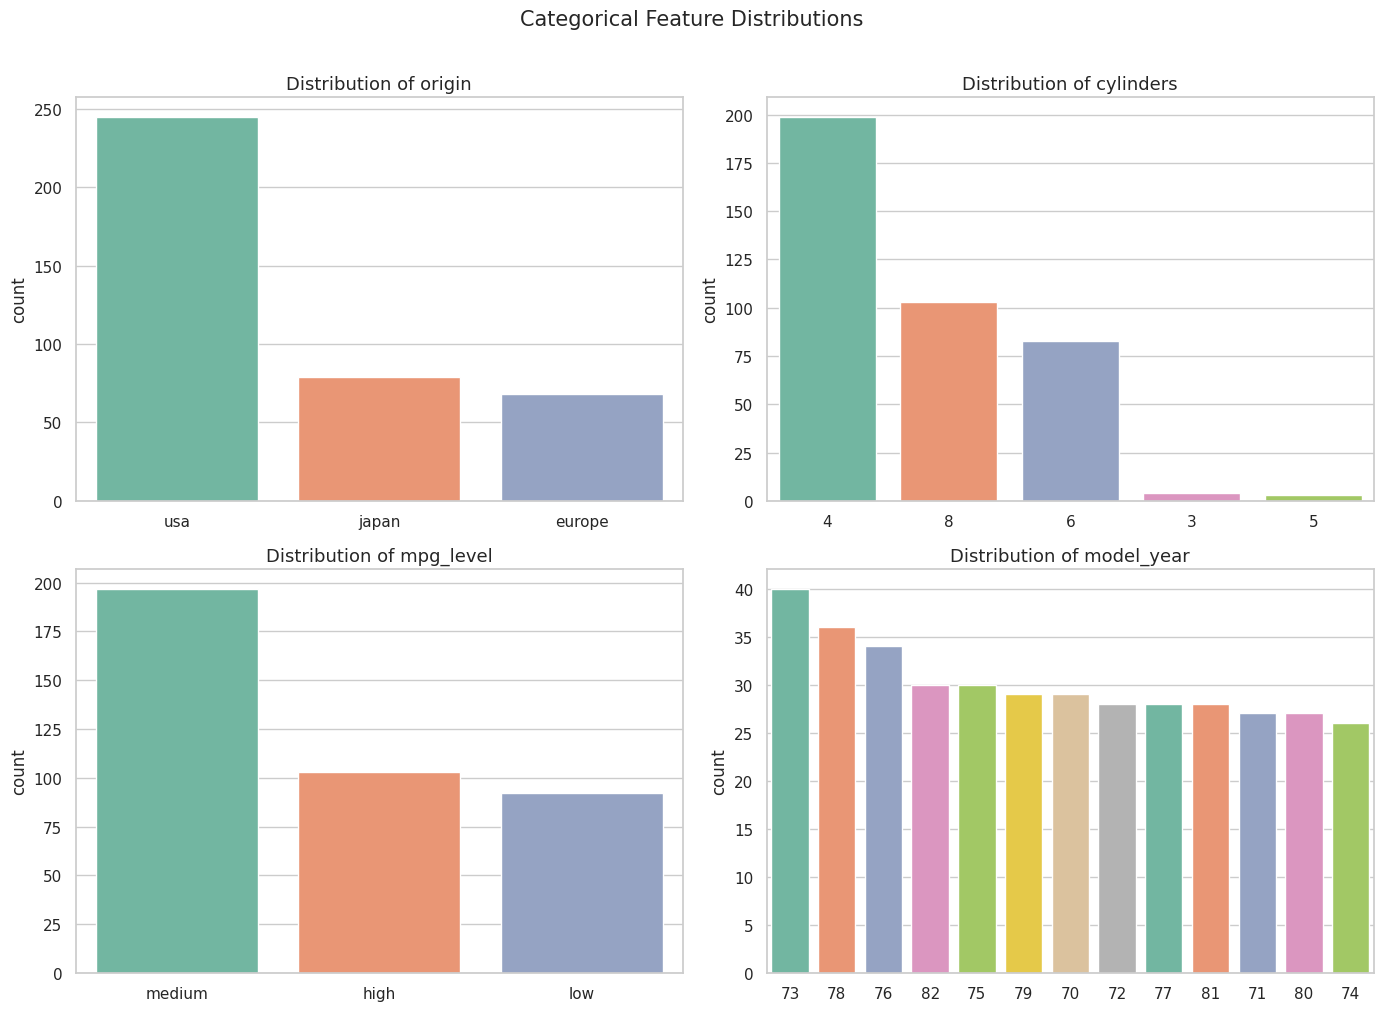

In [ ]:
# TODO: Plot a countplot for each of: origin, cylinders, mpg_level, model_year
# Arrange them in a 2×2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
cat_plot_cols = ['origin','cylinders','mpg_level','model_year']

for ax, col in zip(axes.flat, cat_plot_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, palette='Set2')
    ax.set_title(f'Distribution of {col}', fontsize=13)
    ax.set_xlabel('')

plt.suptitle('Categorical Feature Distributions', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()


In [ ]:
# TODO: Print the proportion (%) of the dominant class for
# origin, cylinders, and mpg_level
for col in ['origin', 'cylinders', 'mpg_level']:
    if col in df.columns:
        dominant_prop = df[col].value_counts(normalize=True).max() * 100
        print(f"Dominant proportion for {col}: {dominant_prop:.2f}%")
    else:
        print(f"Column '{col}' not found (ensure it was created in a previous cell).")


Dominant proportion for origin: 62.50%
Dominant proportion for cylinders: 50.77%
Dominant proportion for mpg_level: 50.26%



--- Crosstab ---
 origin     europe  japan  usa
cylinders                    
3               0      4    0
4              61     69   69
5               3      0    0
6               4      6   73
8               0      0  103


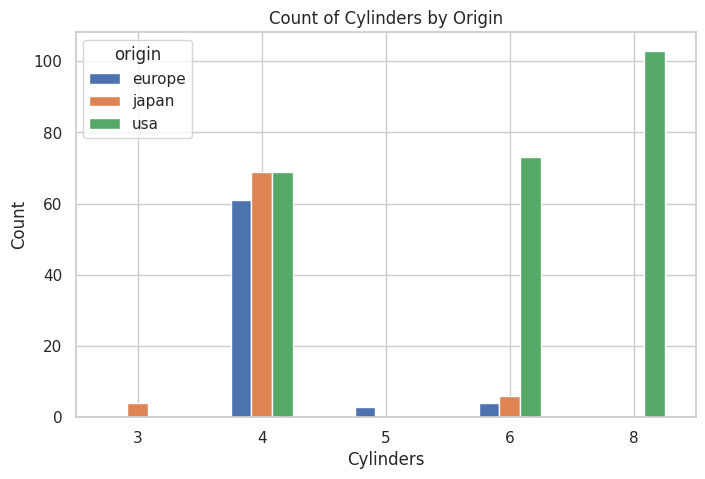

In [ ]:
# TODO: Create a crosstab of cylinders vs origin and visualise as a bar chart
cyl_origin_ct = pd.crosstab(df['cylinders'], df['origin'])
print("\n--- Crosstab ---\n", cyl_origin_ct)

cyl_origin_ct.plot(kind='bar', figsize=(8, 5))
plt.title('Count of Cylinders by Origin')
plt.xlabel('Cylinders')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()


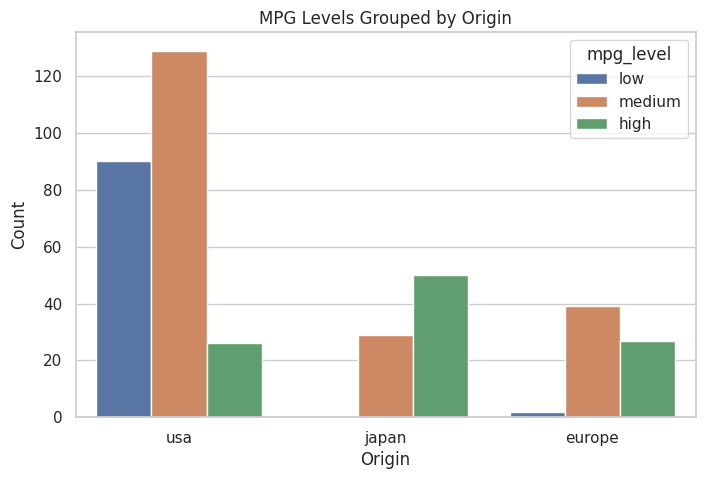

In [ ]:
# TODO: Plot a countplot of mpg_level grouped by origin (use hue='mpg_level')
if 'mpg_level' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x='origin', hue='mpg_level')
    plt.title('MPG Levels Grouped by Origin')
    plt.xlabel('Origin')
    plt.ylabel('Count')
    plt.show()


**Q3.** Which origin has **no** vehicles with low mpg_level?  
**Answer:** Japan

**Q4.** Which cylinder count is most common, and what percentage does it represent?  
**Answer:** 4 cylinders (roughly 50%).


## Task 6 — Numerical EDA

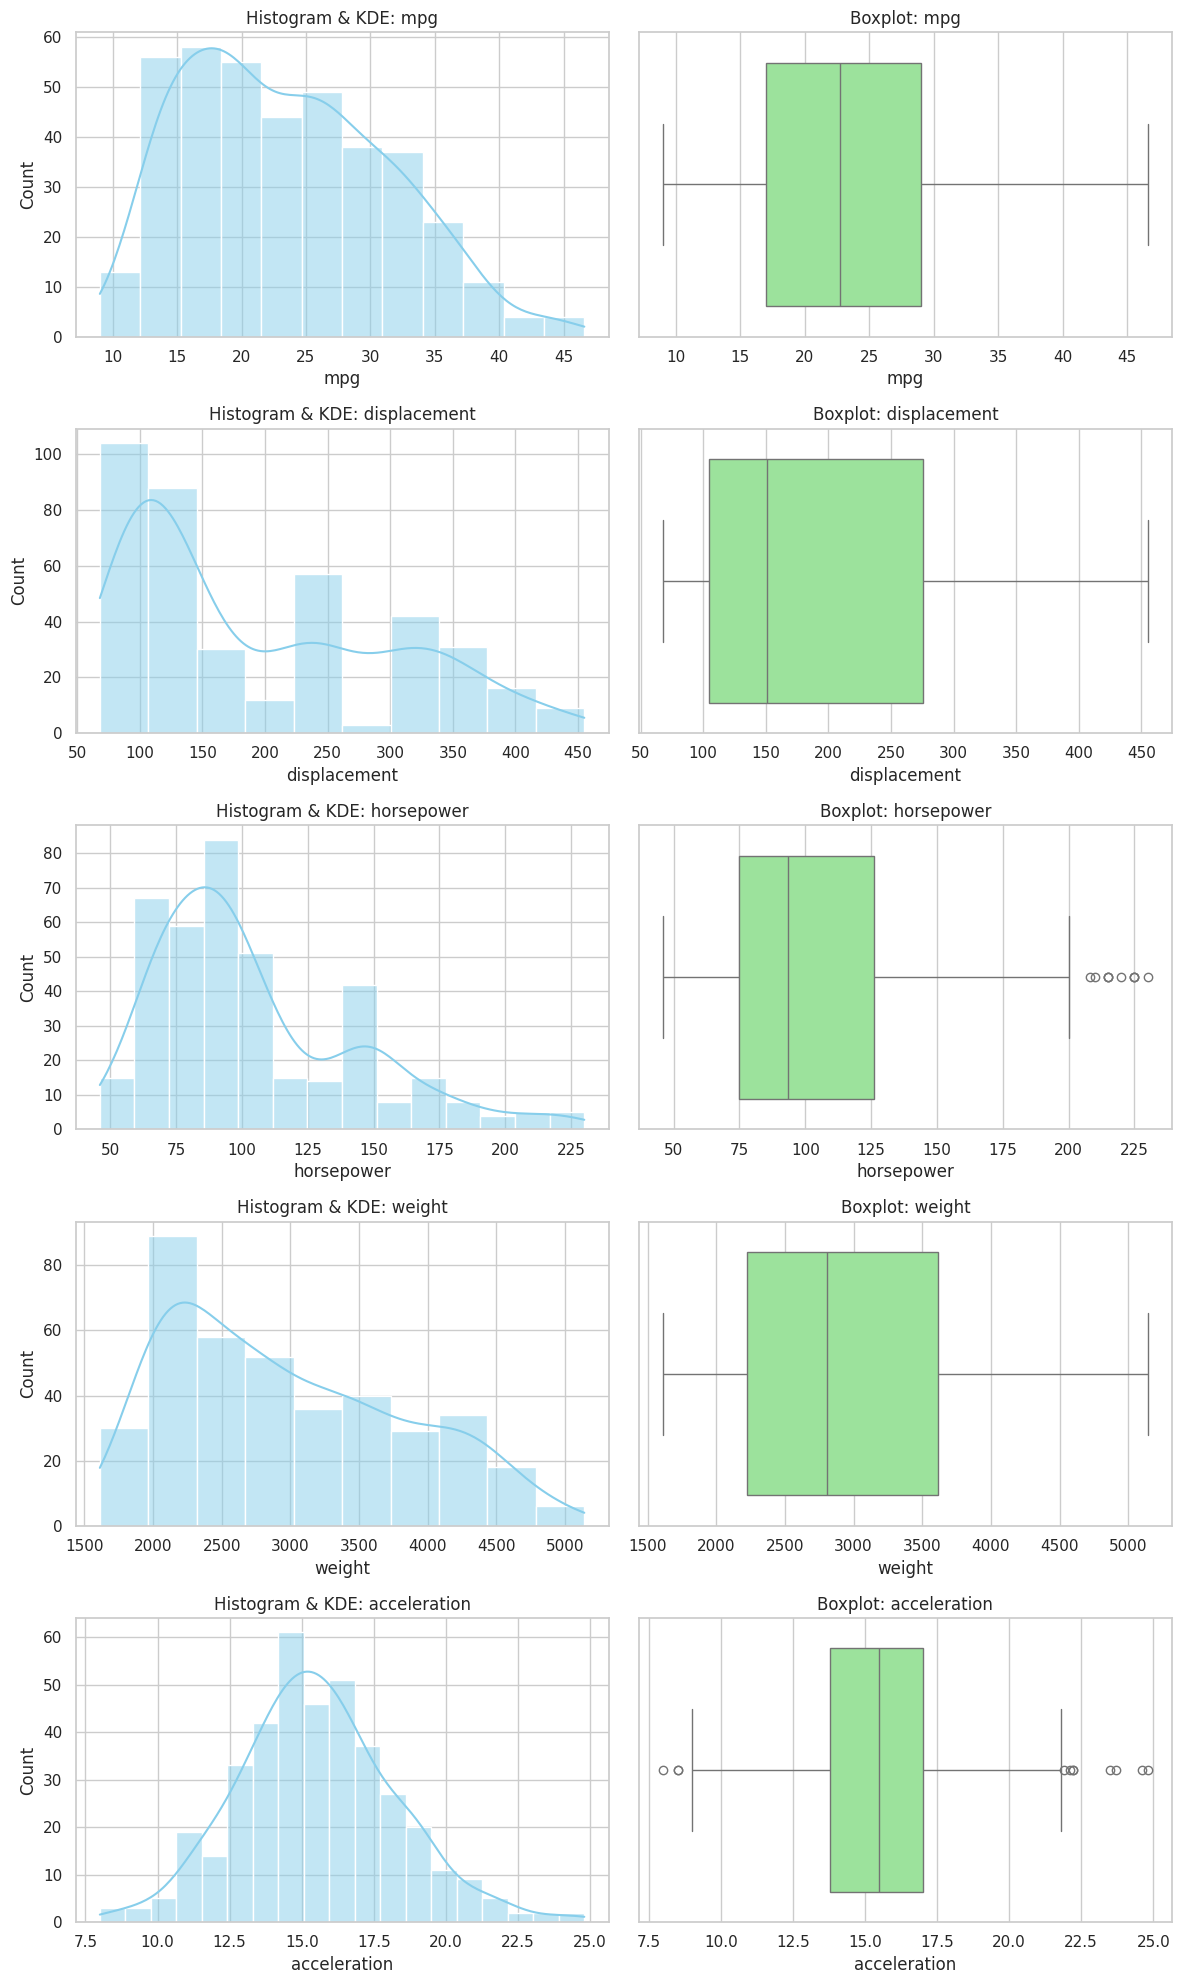

In [ ]:
# TODO: For each numerical column plot:
#   (a) Histogram + KDE  (b) Boxplot
# Arrange in a grid (n_cols rows × 2 columns)

n_cols = len(num_cols)
fig, axes = plt.subplots(nrows=n_cols, ncols=2, figsize=(12, 4 * n_cols))

for i, col in enumerate(num_cols):
    # (a) Histogram + KDE
    sns.histplot(data=df, x=col, kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Histogram & KDE: {col}')

    # (b) Boxplot
    sns.boxplot(data=df, x=col, ax=axes[i, 1], color='lightgreen')
    axes[i, 1].set_title(f'Boxplot: {col}')

plt.tight_layout()
plt.show()

In [ ]:
# TODO: Write a function tukey_outliers(series) that returns the outlier values
# using the IQR (Tukey) rule: Q1 - 1.5*IQR  and  Q3 + 1.5*IQR
# Then print the outlier count for each numerical column

def tukey_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Return values that fall outside the bounds
    return series[(series < lower_bound) | (series > upper_bound)]

print("Outlier counts per numerical column:")
for col in num_cols:
    outliers = tukey_outliers(df[col])
    print(f"{col}: {len(outliers)}")

Outlier counts per numerical column:
mpg: 0
displacement: 0
horsepower: 10
weight: 0
acceleration: 11


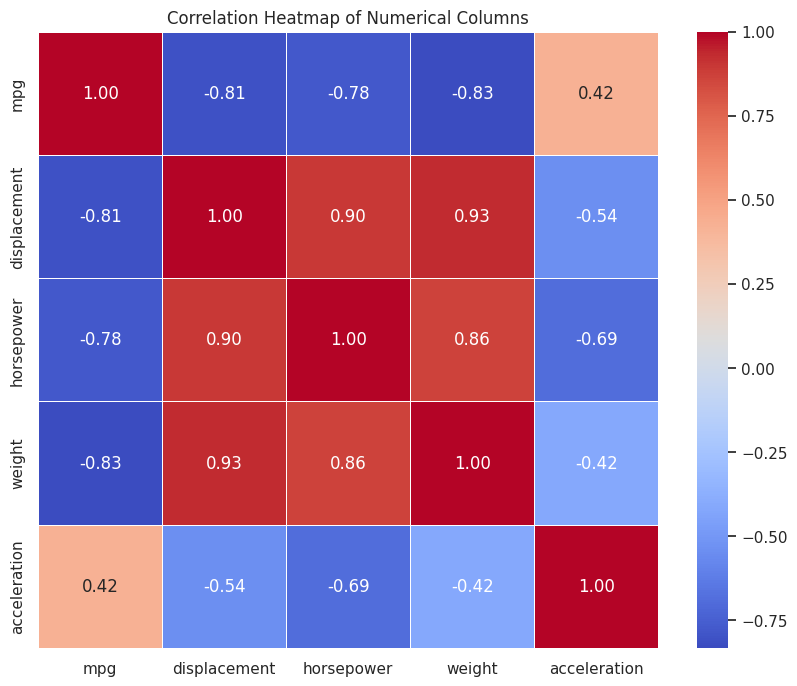

In [ ]:
# TODO: Plot a correlation heatmap for all numerical columns (use annot=True)
plt.figure(figsize=(10, 8))
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Columns')
plt.show()


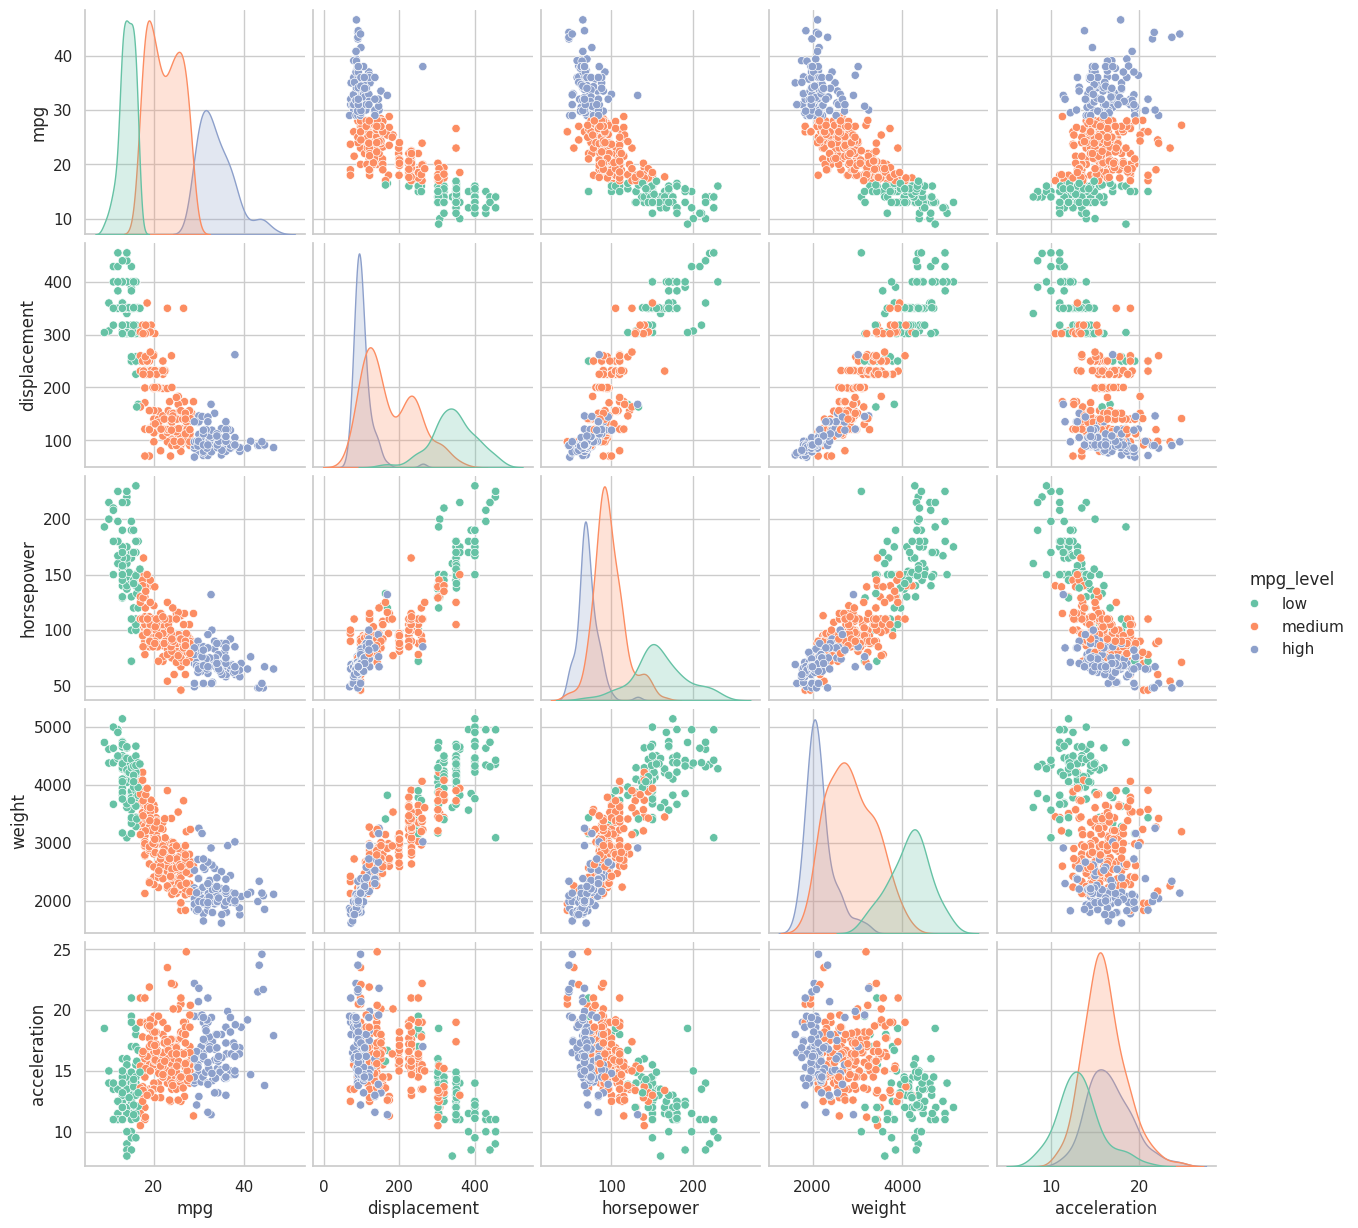

In [ ]:
# TODO: Create a pairplot of numerical columns, coloured by mpg_level
if 'mpg_level' in df.columns:
    sns.pairplot(df, vars=num_cols, hue='mpg_level', palette='Set2')
    plt.show()
else:
    print("Column 'mpg_level' not found. Ensure it was created in a previous cell.")


**Q5.** Which two numerical features have the strongest negative correlation with mpg?  
**Answer:** weight and displacement

**Q6.** Is the `acceleration` distribution approximately Gaussian? Justify briefly.  
**Answer:** Yes. It is roughly symmetric and bell-shaped, clustering around a central mean (around 15.5), which is characteristic of a normal distribution.


## Task 7 — Numerical vs Categorical

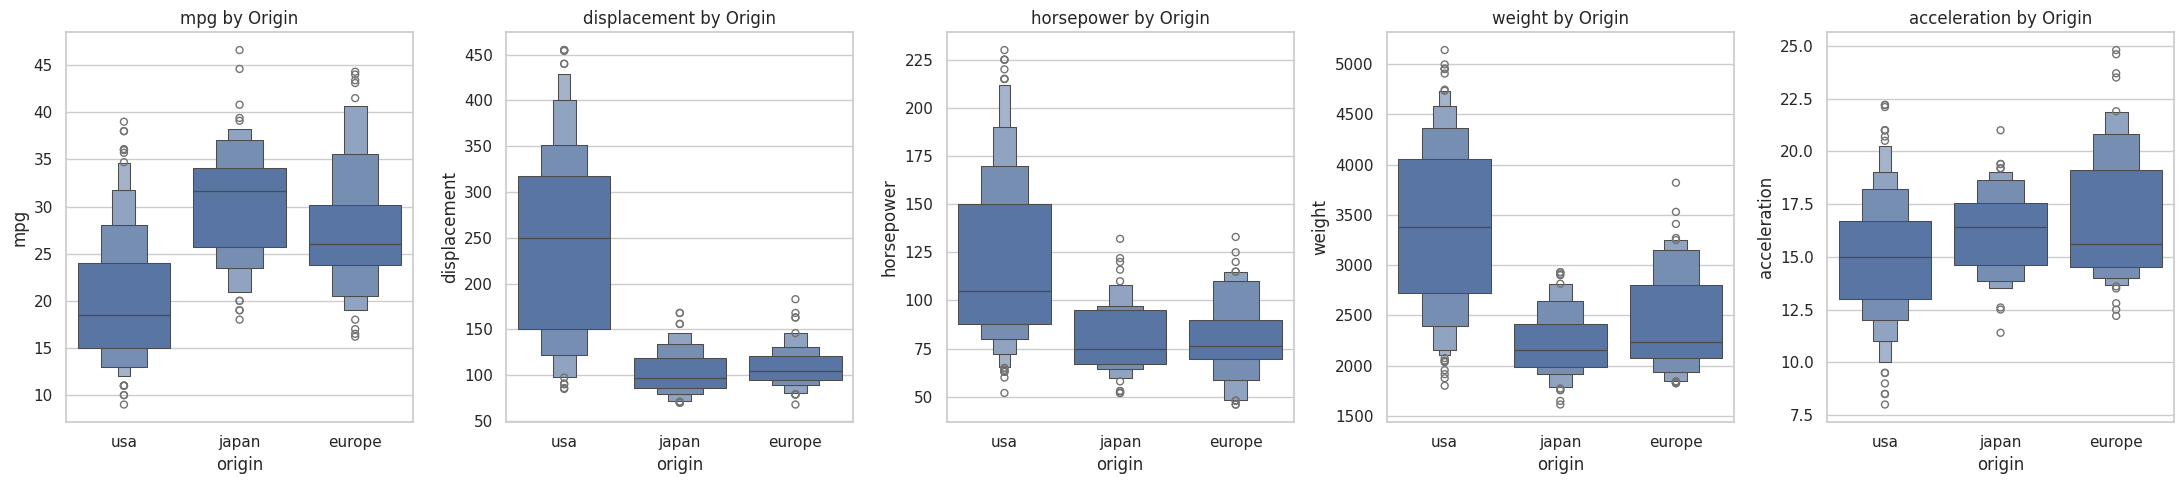

In [ ]:
# TODO: Plot boxenplots of all numerical features grouped by 'origin'
# (1 row × 5 column subplot grid)
continuous_cols = ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']

fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(22, 5))
for i, col in enumerate(continuous_cols):
    sns.boxenplot(data=df, x='origin', y=col, ax=axes[i])
    axes[i].set_title(f'{col} by Origin')
plt.tight_layout()
plt.show()


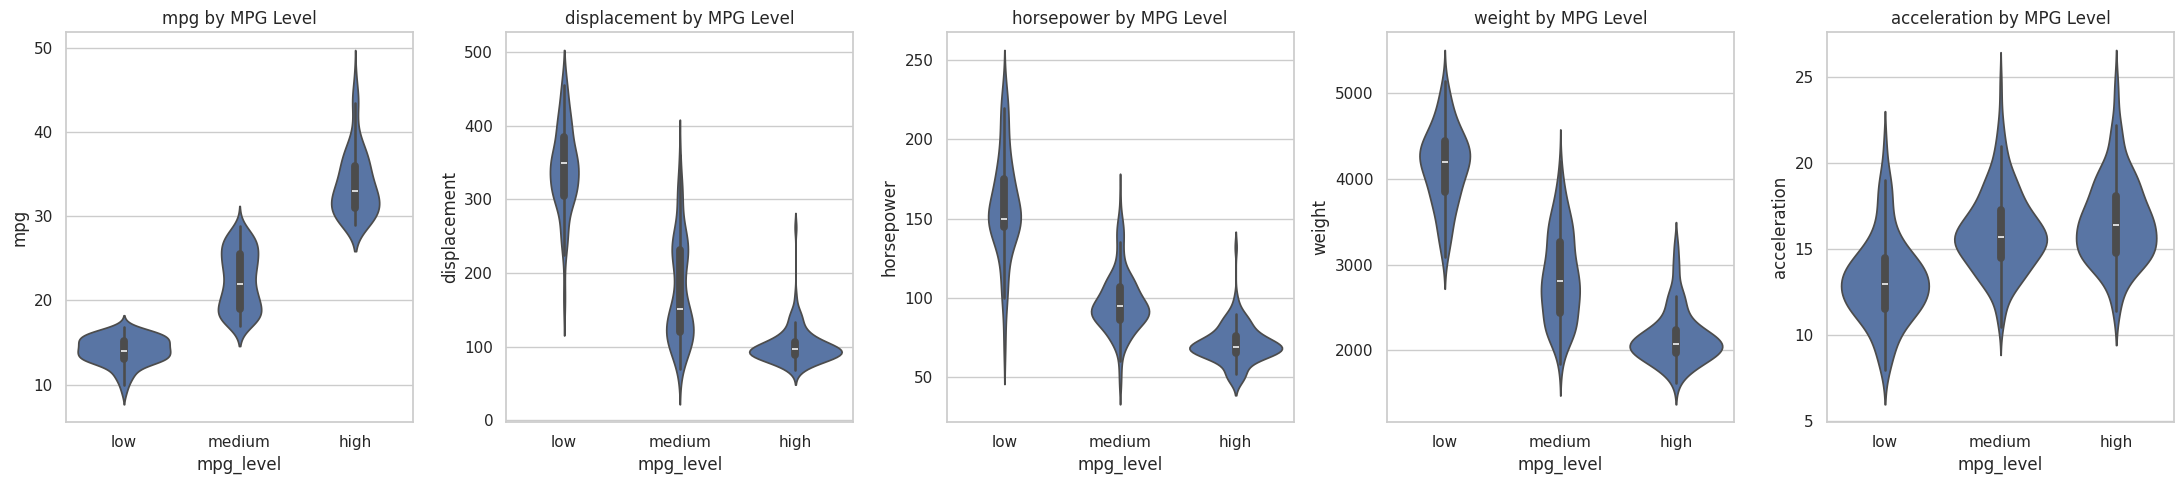

In [ ]:
# TODO: Plot violinplots of all numerical features grouped by 'mpg_level'
fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(22, 5))
for i, col in enumerate(continuous_cols):
    sns.violinplot(data=df, x='mpg_level', y=col, ax=axes[i])
    axes[i].set_title(f'{col} by MPG Level')
plt.tight_layout()
plt.show()


/tmp/ipykernel_535/3314977001.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_mpg = df.groupby('model_year')['mpg'].mean().reset_index()


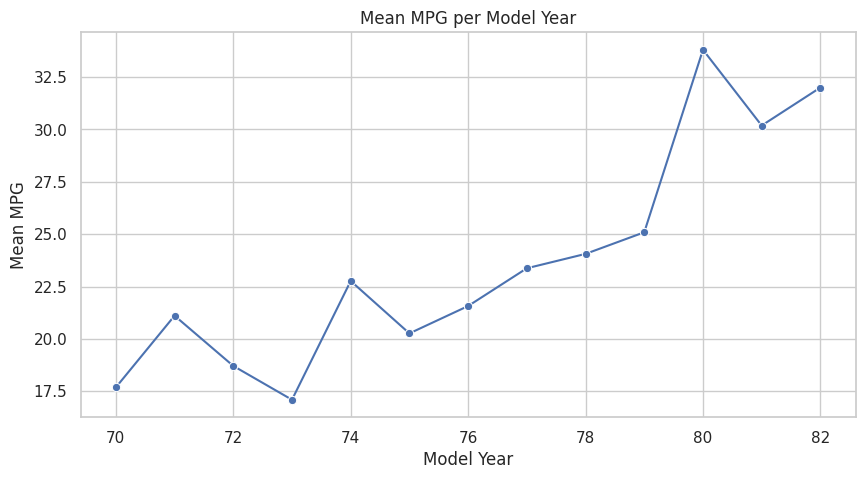

In [ ]:
# TODO: Plot a line chart showing mean mpg per model_year
plt.figure(figsize=(10, 5))
mean_mpg = df.groupby('model_year')['mpg'].mean().reset_index()
sns.lineplot(data=mean_mpg, x='model_year', y='mpg', marker='o', color='b')
plt.title('Mean MPG per Model Year')
plt.xlabel('Model Year')
plt.ylabel('Mean MPG')
plt.grid(True)
plt.show()


**Q7.** On average, which origin produces cars with the lowest mpg?  
**Answer:** usa (Origin 1)

**Q8.** Describe in one sentence how mpg changes as model_year increases.  
**Answer:** As model_year increases, the average mpg generally trends upward, indicating that cars became increasingly fuel-efficient over time.

## Task 8 — Summary Table
Fill in the table below based on your analysis.

| Feature | Relationship with MPG | Strength |
|---|---|---|
| displacement |Neg | |Strong
| horsepower |Neg | |Strong
| weight |Neg | |Strong
| acceleration |Pos | |Moderate
| cylinders |Neg | |Strong
| origin |Pos | |Moderate
| model_year |Pos | |Strong
